# Figure 1 depth companion: feature-expression correlation versus sequencing depth

The Fig 1c correlation (per-sample Pearson r between each feature and Esfahani et al. PBMC gene-group
expression) for the same 50 panel-of-normals samples at native depth and after in-code downsampling to
1x and 0.1x (seed 42).

- (a) all TSSs; (b) QC TSSs. Native depth is drawn at the panel's median depth.

Source data (written by `export/export_fig1_depth.py`, run with `COHORT_VARIANT=all`):
- `data/fig1_depth_correlations.csv` (native rows equal `fig1c_expression_correlations.csv`, asserted)
- `data/fig1_depth_cohort_coverage.csv`

Run top to bottom from `src/figures/`.

In [1]:
import os
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import _figstyle as fs
fs.apply()

FEATURE_NAMES = {"fslr": "FSLR", "fslr_coverage": "FSLRC", "griffin_diff": "GD",
                 "rcov": "RCOV", "mwh": "MWH"}
FEATURE_COLORS = {f: fs.FEATURE[n] for f, n in FEATURE_NAMES.items()}
FEATURES = list(FEATURE_NAMES)

corr = pd.read_csv("data/fig1_depth_correlations.csv")
cohort = pd.read_csv("data/fig1_depth_cohort_coverage.csv")
pon_depth = cohort.loc[cohort.group == "panel_of_normals", "mean_coverage"]
DEPTH_X = {"0.1x": 0.1, "1x": 1.0, "native": float(pon_depth.median())}
N = corr["sample_id"].nunique()
print(f"panel of normals: n = {N}, native depth median {DEPTH_X['native']:.2f}x "
      f"(range {pon_depth.min():.2f}-{pon_depth.max():.2f})")
print(cohort.groupby("group")["mean_coverage"].describe().round(2).to_string())

panel of normals: n = 50, native depth median 2.58x (range 1.78-3.91)
                  count  mean   std   min   25%   50%    75%    max
group                                                              
cohort            367.0  2.48  0.57  1.06  2.13  2.42   2.76   5.25
deep_excluded      30.0  9.89  1.93  6.35  8.78  9.59  10.88  13.81
panel_of_normals   50.0  2.68  0.59  1.78  2.22  2.58   3.12   3.91


## Summary table: mean ± SD of r over the 50 samples

In [2]:
summ = (corr.groupby(["tss_set", "feature", "depth"])["pearson_r"]
        .agg(mean="mean", sd=lambda v: v.std(ddof=0)).reset_index())
tab = summ.assign(cell=summ["mean"].map("{:+.3f}".format) + " ± " + summ["sd"].map("{:.3f}".format))
tab = tab.pivot(index=["tss_set", "feature"], columns="depth", values="cell")[["native", "1x", "0.1x"]]
tab

depth                          native              1x            0.1x
tss_set feature                                                      
all     fslr           +0.713 ± 0.038  +0.572 ± 0.038  +0.432 ± 0.028
        fslr_coverage  +0.708 ± 0.038  +0.565 ± 0.038  +0.251 ± 0.040
        griffin_diff   +0.711 ± 0.027  +0.613 ± 0.022  +0.275 ± 0.027
        mwh            -0.278 ± 0.038  -0.310 ± 0.030  -0.171 ± 0.022
        rcov           -0.269 ± 0.150  -0.188 ± 0.075  -0.051 ± 0.027
qc      fslr           +0.739 ± 0.038  +0.594 ± 0.040  +0.452 ± 0.042
        fslr_coverage  +0.738 ± 0.037  +0.590 ± 0.040  +0.256 ± 0.055
        griffin_diff   +0.749 ± 0.030  +0.642 ± 0.027  +0.292 ± 0.044
        mwh            -0.313 ± 0.044  -0.332 ± 0.037  -0.173 ± 0.037
        rcov           -0.400 ± 0.082  -0.248 ± 0.055  -0.070 ± 0.049

## Assemble the figure

saved output/fig1_depth.png/.pdf at 125 x 64 mm


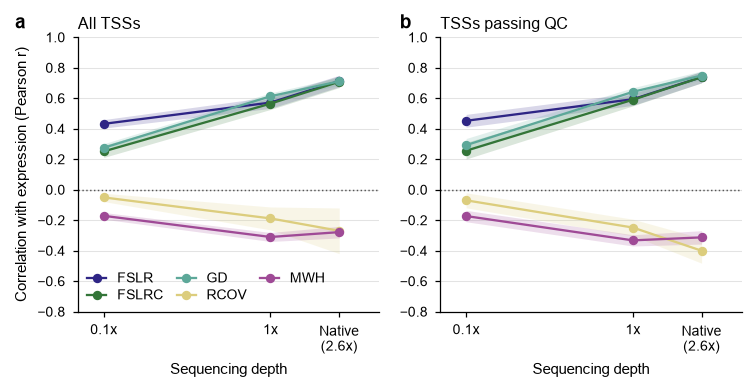

In [3]:
def depth_panel(ax, tss_set):
    for feat in FEATURES:
        s = summ[(summ.tss_set == tss_set) & (summ.feature == feat)].copy()
        s["x"] = s["depth"].map(DEPTH_X)
        s = s.sort_values("x")
        c = FEATURE_COLORS[feat]
        ax.plot(s["x"], s["mean"], "-o", color=c, label=FEATURE_NAMES[feat], zorder=3)
        ax.fill_between(s["x"], s["mean"] - s["sd"], s["mean"] + s["sd"], color=c, alpha=0.18, lw=0, zorder=2)
    ax.axhline(0, color=fs.CHANCE, ls=":", lw=0.7, zorder=1)
    ax.set_xscale("log")
    ax.set_xticks(list(DEPTH_X.values()))
    ax.set_xticklabels(["0.1x", "1x", f"Native\n({DEPTH_X['native']:.1f}x)"])
    ax.minorticks_off()
    ax.set_xlim(0.07, 4.5)
    ax.set_xlabel("Sequencing depth")
    fs.value_grid(ax)

GROUPS = [("cohort", "Revised\ncohort", "#6b6b6b"),
          ("panel_of_normals", "Panel of\nnormals", "#2e2585"),
          ("deep_excluded", "Deep healthy\n(excluded)", "#c26a77")]

def cohort_panel(ax):
    rng = np.random.default_rng(0)
    for i, (g, label, color) in enumerate(GROUPS):
        v = cohort.loc[cohort.group == g, "mean_coverage"].to_numpy()
        y = i + rng.uniform(-0.25, 0.25, len(v))
        ax.scatter(v, y, s=12, color=color, alpha=0.6, lw=0)
        ax.plot([np.median(v)] * 2, [i - 0.35, i + 0.35], color="k", lw=2)
        ax.text(16, i, f"n = {len(v)}\nmedian {np.median(v):.1f}x", va="center", fontsize=10)
    for t in (0.1, 1.0):
        ax.axvline(t, color="k", ls="--", lw=1, alpha=0.6)
    ax.set_xscale("log")
    ax.set_xlim(0.07, 40)
    ax.set_xticks([0.1, 1, 2, 5, 10])
    ax.set_xticklabels(["0.1x", "1x", "2x", "5x", "10x"])
    ax.minorticks_off()
    ax.set_yticks(range(len(GROUPS)))
    ax.set_yticklabels([l for _, l, _ in GROUPS], fontsize=11)
    ax.invert_yaxis()
    ax.set_xlabel("Mean sequencing depth per sample", fontsize=13)
    ax.set_title("Sample depth (dashed: downsampling targets)", fontsize=13)
    ax.grid(True, alpha=0.3, linestyle="--", axis="x")
    ax.tick_params(labelsize=11)

# cohort_panel() (a per-sample depth strip) is not drawn
# Drawn at 0.7 x the full figure width: the manuscript includes this figure at width=0.7\textwidth, so 7 pt here is 7 pt in print.
FIG_W = 0.7 * fs.WIDTH
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(FIG_W, 2.5), layout="constrained", sharey=True)
depth_panel(ax_a, "all")
depth_panel(ax_b, "qc")
fs.panel(ax_a, "a", "All TSSs")
fs.panel(ax_b, "b", "TSSs passing QC")
ax_a.set_ylabel("Correlation with expression (Pearson r)")
ax_b.tick_params(labelleft=True)      # tick labels on both panels: the letter then sits clear of the title
ax_a.legend(loc="lower left", ncol=3, columnspacing=1.0, handlelength=1.4)
ax_a.set_ylim(-0.8, 1.0)
os.makedirs("output", exist_ok=True)
fs.save(fig, "output/fig1_depth")
plt.show()


## Checks

Native-depth values equal Fig 1c (the exporter asserts this).

In [4]:
q = summ[summ.tss_set == "qc"].set_index(["feature", "depth"])["mean"]
for f in ["fslr", "fslr_coverage", "griffin_diff"]:
    assert q[(f, "native")] > q[(f, "1x")] > q[(f, "0.1x")], f
    assert q[(f, "1x")] > 0.5, f
print("checks passed")

checks passed
